# code_097 · Contextual and structured anomalies

**Book:** section 19.5. A self-contained clustering-and-anomaly laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_19_GUIDE.md), [run evidence](../CHAPTER_19_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_097).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1997;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1997


<a id="context"></a>
## A locally inconsistent connection can be globally ordinary

Ten connections form a declared ring; each averages its two neighbors with weights.5. Generate80reference/80independent calibration/120final time steps, five minutes per step. Readings=2*known commonload+fixed connectionoffset+common ambient sinusoid+independent noiseSD.03, in declared response units. Reference/calibration loads uniform[.2,.9]. In final, connection4 (zero-based ID) receives+.3 at steps50–59 with load.8. Steps80–89 instead have valid commonload1.5 at ALLconnections, with no local implant. These are synthetic response perturbations, not validated structural damage.

Fit three fixed scores using admitted reference only: per-connection absolute raw z, absolute neighbor-contrast z after removing training contrast mean, and PCA1reconstruction residual z. All contemporaneous neighboring readings are assumed available at that step; no future reading enters a point score. Independent calibration sets each99th percentile threshold over800sensor checks. Thresholds are not selected from final event labels. Repeat the declared fits with a contaminated reference that adds+.3 to connection4 in30of80reference steps, retaining the same clean calibration. A changed reference can mask an implant or increase burden. Neighbor contrast can also flag adjacent connections when one reading changes; record those false point flags rather than claiming perfect localization.


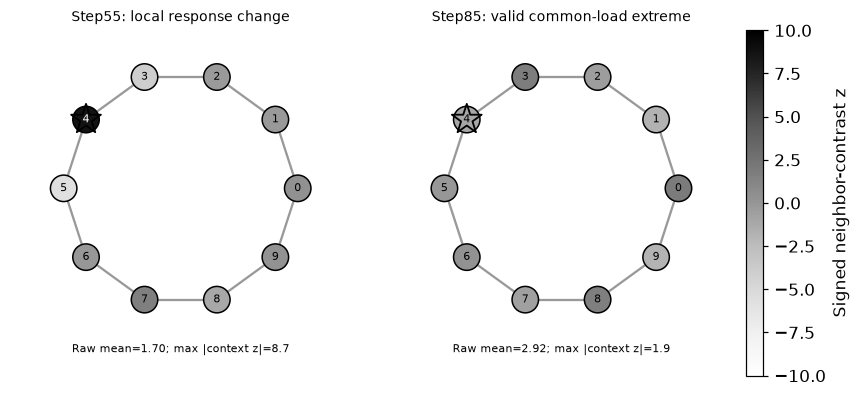

In [2]:
from sklearn.decomposition import PCA
NODES=10;W=np.zeros((NODES,NODES))
for i in range(NODES):W[i,(i-1)%NODES]=.5;W[i,(i+1)%NODES]=.5
np.testing.assert_allclose(W.sum(axis=1),1);np.testing.assert_allclose(W,W.T);offset=rng.normal(0,.05,NODES)
def readings(n,role):
 load=rng.uniform(.2,.9,n)
 if role=='final':load[50:60]=.8;load[80:90]=1.5
 common=2*load+.1*np.sin(np.arange(n)/8);value=common[:,None]+offset+rng.normal(0,.03,(n,NODES))
 if role=='final':value[50:60,4]+=.3
 return load,value
ref_load,reference=readings(80,'reference');cal_load,calibration=readings(80,'calibration');test_load,test=readings(120,'final');truth=np.zeros_like(test,dtype=bool);truth[50:60,4]=True;contaminated=reference.copy();contaminated[10:40,4]+=.3
class Scores:
 def __init__(self,a):
  self.mean=a.mean(axis=0);self.sd=a.std(axis=0,ddof=1);contrast=a-a@W.T;self.cm=contrast.mean(axis=0);self.cs=contrast.std(axis=0,ddof=1);self.pca=PCA(1,svd_solver='full').fit(a);res=a-self.pca.inverse_transform(self.pca.transform(a));self.rs=res.std(axis=0,ddof=1);assert np.all(self.sd>0)&np.all(self.cs>0)&np.all(self.rs>0)
 def signed_context(self,a):return (a-a@W.T-self.cm)/self.cs
 def score(self,a):
  residual=a-self.pca.inverse_transform(self.pca.transform(a));return {'Global raw':np.abs((a-self.mean)/self.sd),'Graph context':np.abs(self.signed_context(a)),'PCA reconstruction':np.abs(residual/self.rs)}
fits={'Admitted clean':Scores(reference),'Contaminated reference':Scores(contaminated)};rows=[];flags={};thresholds={};final_scores={};normal_checks=int((~truth).sum());hours=len(test)*5/60
for role,fit in fits.items():
 c=fit.score(calibration);t=fit.score(test);final_scores[role]=t
 for name,value in t.items():
  threshold=float(np.quantile(c[name],.99));alarm=value>threshold;assert alarm.shape==truth.shape and np.isfinite(value).all();tp=int(np.sum(alarm&truth));fp=int(np.sum(alarm&~truth));flags[(role,name)]=alarm;thresholds[(role,name)]=threshold;rows.append({'reference':role,'score':name,'calibration_threshold':threshold,'true_event_point_flags':tp,'event_point_denominator':10,'false_point_flags':fp,'normal_sensor_checks':normal_checks,'false_flags_per_1000_normal_checks':1000*fp/normal_checks,'false_point_flags_per_operating_hour':fp/hours,'valid_extreme_window_flags':int(alarm[80:90].sum())})
RESULTS['point_alarms']=rows;RESULTS['contract']={'connections':10,'reference_steps':80,'calibration_steps':80,'final_steps':120,'minutes_per_step':5,'final_operating_hours':hours,'event_connection_zero_based':4,'event_steps_inclusive':[50,59],'valid_commonload_extreme_steps_inclusive':[80,89],'contemporaneous_neighbors_available':True,'future_readings_used_for_point_scores':False,'contaminated_reference_steps':30,'calibration_sensor_checks':800,'point_threshold_quantile':.99,'flags_are_independent_events':False}
angles=np.arange(10)*2*np.pi/10;position=np.column_stack([np.cos(angles),np.sin(angles)]);fig,axes=plt.subplots(1,2,figsize=(8,3.5));signed=fits['Admitted clean'].signed_context(test)
for ax,step,title in zip(axes,[55,85],['Step55: local response change','Step85: valid common-load extreme']):
 for i in range(10):j=(i+1)%10;ax.plot(position[[i,j],0],position[[i,j],1],color='.6',zorder=0)
 im=ax.scatter(*position.T,c=signed[step],cmap='Greys',vmin=-10,vmax=10,s=300,edgecolors='black');ax.scatter(*position[4],marker='*',s=420,facecolors='none',edgecolors='black',linewidths=1.2)
 for i,(x0,y0) in enumerate(position):ax.text(x0,y0,str(i),ha='center',va='center',fontsize=7,color='white' if signed[step,i]>2 else 'black')
 ax.text(0,-1.4,f'Raw mean={test[step].mean():.2f}; max |context z|={np.abs(signed[step]).max():.1f}',ha='center',fontsize=7);ax.set(title=title,aspect='equal',xlim=(-1.45,1.45),ylim=(-1.6,1.35));ax.axis('off')
fig.colorbar(im,ax=axes,fraction=.025,pad=.02,label='Signed neighbor-contrast z');plt.show()


<a id="timing"></a>
## Distinguish point flags, sequential alerts and selective review

A one-sided CUSUM uses clean-reference signed graph residuals for connection4, drift allowance.5. Its predeclared threshold rule is max(5,maximum calibration cumulative statistic), using calibration only; this finite rule is not a false-alarm guarantee. On an alert, reset tozero and skip the next five time steps. Report event first-alert delay, false alert times and alerts/hour separately from pointwise flag counts. Sequence accumulation can detect a persistent deviation that an isolated-point rule would treat differently.

For a simulated incomplete review ledger, sort final graph point flags by score and review every second flag, retaining all unreviewed flags as unknown. Generator truth permits a separate oracle audit here, but unreviewed real cases cannot become presumed true negatives. Precision among selectively reviewed flags does not estimate population precision without a review-sampling account. No review feedback changes thresholds on this frozen assessment; a changed detector requires later evidence. PCAreconstruction and graph inconsistency define different deviations, not causal diagnoses.


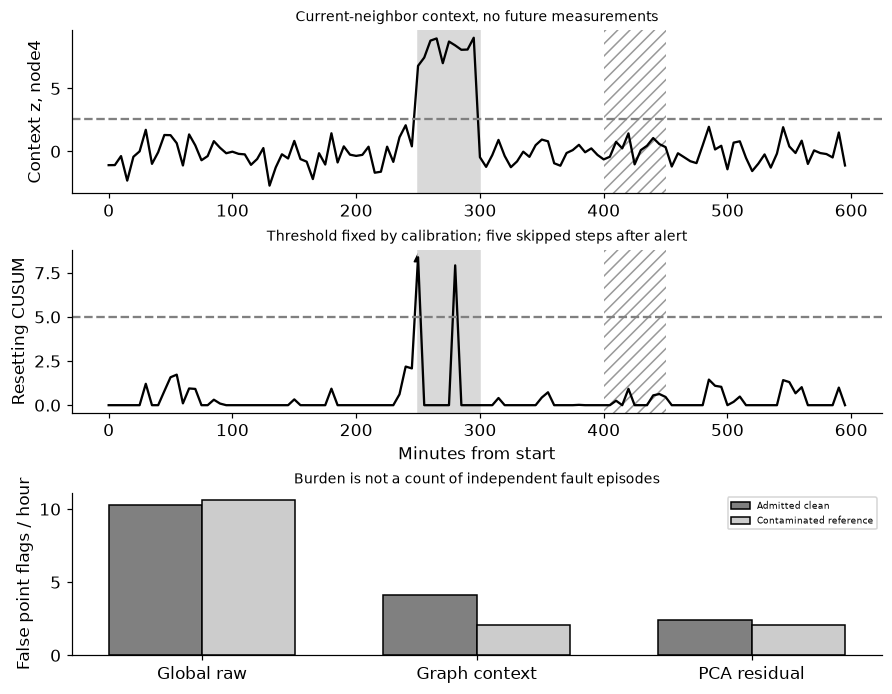

In [3]:
fit=fits['Admitted clean'];cal_series=fit.signed_context(calibration)[:,4];state=0.;cal_trace=[]
for z in cal_series:state=max(0.,state+z-.5);cal_trace.append(state)
h=float(max(5.,max(cal_trace)))
def cusum(series,threshold):
 state=0.;cooldown=0;trace=[];alerts=[]
 for i,z in enumerate(series):
  if cooldown:cooldown-=1;trace.append(0.);continue
  state=max(0.,state+z-.5);trace.append(state)
  if state>threshold:alerts.append(i);state=0.;cooldown=5
 return np.array(trace),alerts
trace,alerts=cusum(fit.signed_context(test)[:,4],h);event=[i for i in alerts if 50<=i<60];false=[i for i in alerts if not 50<=i<60];delay=(event[0]-50)*5 if event else None;assert all(b-a>=6 for a,b in zip(alerts,alerts[1:]));assert h>=max(cal_trace)
alarmed=np.argwhere(flags[('Admitted clean','Graph context')]);scores=final_scores['Admitted clean']['Graph context'];order=np.argsort([-scores[t,j] for t,j in alarmed]);ordered=alarmed[order];reviewed=ordered[::2];unreviewed=ordered[1::2];true_reviewed=int(sum(bool(truth[t,j]) for t,j in reviewed));assert len(reviewed)+len(unreviewed)==len(alarmed)
RESULTS['sequence_alerts']={'connection':4,'CUSUM_drift':.5,'threshold':h,'threshold_rule':'max(5,maximum unreset calibration statistic)','refractory_skipped_steps':5,'alert_steps':alerts,'event_alert_steps':event,'false_alert_steps':false,'first_event_delay_minutes':delay,'false_alerts_per_operating_hour':len(false)/hours,'final_threshold_changed':False};RESULTS['review_ledger']={'graph_point_flags':len(alarmed),'reviewed':len(reviewed),'reviewed_oracle_true':true_reviewed,'reviewed_oracle_false':len(reviewed)-true_reviewed,'unreviewed_status_unknown':len(unreviewed),'selectively_reviewed_precision':true_reviewed/len(reviewed) if len(reviewed) else None,'unknown_counted_as_true_negative':False,'feedback_used_to_retune_final':False};RESULTS['illustrated_snapshots']=[{'step':t,'raw_mean':float(test[t].mean()),'max_abs_context_z':float(np.abs(signed[t]).max())} for t in [55,85]]
fig,axes=plt.subplots(3,1,figsize=(8,6.2));minutes=np.arange(120)*5;axes[0].plot(minutes,fit.signed_context(test)[:,4],color='black');axes[0].axhline(thresholds[('Admitted clean','Graph context')],color='.5',ls='--');axes[0].set(ylabel='Context z, node4',title='Current-neighbor context, no future measurements');axes[1].plot(minutes,trace,color='black');axes[1].axhline(h,color='.5',ls='--');axes[1].scatter(np.array(alerts)*5,trace[alerts],marker='^',s=30,color='black');axes[1].set(ylabel='Resetting CUSUM',xlabel='Minutes from start',title='Threshold fixed by calibration; five skipped steps after alert')
for ax in axes[:2]:ax.axvspan(250,300,color='.85');ax.axvspan(400,450,facecolor='none',edgecolor='.6',hatch='///',linewidth=0)
pos=np.arange(3)
for j,role in enumerate(fits):axes[2].bar(pos+(j-.5)*.34,[r['false_point_flags_per_operating_hour'] for r in rows if r['reference']==role],width=.34,color=['.5','.8'][j],edgecolor='black',label=role)
axes[2].set(xticks=pos,xticklabels=['Global raw','Graph context','PCA residual'],ylabel='False point flags / hour',title='Burden is not a count of independent fault episodes');axes[2].legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_097','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['contemporaneous graph residual versus common-mode extremes', 'training-only PCA reconstruction and reference contamination', 'calibration thresholds sequential delay and alarm burden', 'selective review with unreviewed cases kept unknown'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["contemporaneous graph residual versus common-mode extremes", "training-only PCA reconstruction and reference contamination", "calibration thresholds sequential delay and alarm burden", "selective review with unreviewed cases kept unknown"], "elapsed_seconds": 0.35, "example_id": "code_097", "hardware": "Darwin arm64 CPU", "results": {"contract": {"calibration_sensor_checks": 800, "calibration_steps": 80, "connections": 10, "contaminated_reference_steps": 30, "contemporaneous_neighbors_available": true, "event_connection_zero_based": 4, "event_steps_inclusive": [50, 59], "final_operating_hours": 10.0, "final_steps": 120, "flags_are_independent_events": false, "future_readings_used_for_point_scores": false, "minutes_per_step": 5, "point_threshold_quantile": 0.99, "reference_steps": 80, "valid_commonload_extreme_steps_inclusive": [80, 89]}, "illustrated_snapshots": [{"max_abs_context_z": 8.725923422567888, "raw_mean": 1.6958393269308132, 